In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, RocCurveDisplay
)

# Load dataset
df = pd.read_csv('flood_risk_dataset_india.csv')
print(f"Ukuran Dataset: {df.shape}")
df.head()

Ukuran Dataset: (10000, 14)


,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
0,18.861663,78.835584,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465433,Water Body,Clay,7276.742184,1,0,1
1,35.570715,77.654451,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,Forest,Peat,6897.736956,0,1,0
2,29.227824,73.108463,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,Agricultural,Loam,4361.518494,1,1,1
3,25.361096,85.610733,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,Desert,Sandy,6163.069701,1,1,0
4,12.524541,81.822101,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,Agricultural,Loam,6167.964591,1,0,0


In [2]:
X = df.drop(columns=['Flood Occurred'])
y = df['Flood Occurred']

# Stratified split: 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train set      : {X_train.shape[0]} sampel ({y_train.mean():.2%} positif)")
print(f"Validation set : {X_val.shape[0]} sampel ({y_val.mean():.2%} positif)")
print(f"Test set       : {X_test.shape[0]} sampel ({y_test.mean():.2%} positif)")

Train set      : 7000 sampel (50.57% positif)
Validation set : 1500 sampel (50.60% positif)
Test set       : 1500 sampel (50.53% positif)


In [4]:
num_cols = [
    'Latitude', 'Longitude', 'Rainfall (mm)', 'Temperature (°C)', 'Humidity (%)',
    'River Discharge (m³/s)', 'Water Level (m)', 'Elevation (m)', 'Population Density'
]
bin_cols = ['Infrastructure', 'Historical Floods']
cat_cols = ['Land Cover', 'Soil Type']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

# Hyperparameter awal Logistic Regression
baseline_params = {
    'penalty': 'l2',
    'C': 1.0,
    'solver': 'lbfgs',
    'max_iter': 1000,
    'random_state': 42
}

baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(**baseline_params))
])

# Latih model pada training set
baseline_pipeline.fit(X_train, y_train)
print("Hyperparameter Baseline:", baseline_pipeline.named_steps['classifier'].get_params())

Hyperparameter Baseline: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Baseline),0.4867,0.4933,0.5349,0.5133,0.4934



Classification Report (Validation Set):
              precision    recall  f1-score   support

           0     0.4786    0.4372    0.4570       741
           1     0.4933    0.5349    0.5133       759

    accuracy                         0.4867      1500
   macro avg     0.4859    0.4861    0.4851      1500
weighted avg     0.4860    0.4867    0.4855      1500



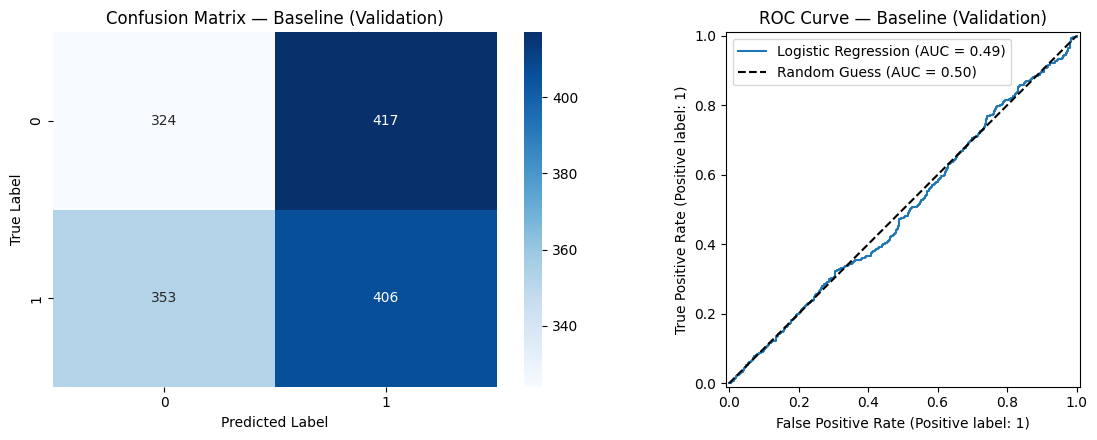

In [5]:
y_val_pred = baseline_pipeline.predict(X_val)
y_val_prob = baseline_pipeline.predict_proba(X_val)[:, 1]

metrics_baseline = pd.DataFrame([{
    'Model': 'Logistic Regression (Baseline)',
    'Accuracy': accuracy_score(y_val, y_val_pred),
    'Precision': precision_score(y_val, y_val_pred),
    'Recall': recall_score(y_val, y_val_pred),
    'F1-Score': f1_score(y_val, y_val_pred),
    'ROC-AUC': roc_auc_score(y_val, y_val_prob)
}])

display(metrics_baseline.round(4))
print("\nClassification Report (Validation Set):")
print(classification_report(y_val, y_val_pred, digits=4))

# Plot Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_val, y_val_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix — Baseline (Validation)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

RocCurveDisplay.from_predictions(y_val, y_val_prob, ax=axes[1], name='Logistic Regression')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')
axes[1].set_title('ROC Curve — Baseline (Validation)')
axes[1].legend()

plt.tight_layout()
plt.show()